# Ask a spatial question

**Foundations · 20 minutes**

A map combines values, geometry, scale, projection and design choices. Before mapping, ask what was measured, where, when, with which units and for whom. Longitude/latitude degrees are not a uniform distance unit. Counts need denominators before comparing rates.

**Question:** Can the nearest location change when distance follows a network? Compare straight-line and grid-route distance for fictional points in arbitrary planar units.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Straight-line: {'A': 5.0, 'B': 6.0, 'C': 5.656854249492381} 
Grid route: {'A': 7, 'B': 6, 'C': 8}
Synthetic route length on an orthogonal grid | planar units: {'A': 7, 'B': 6, 'C': 8}


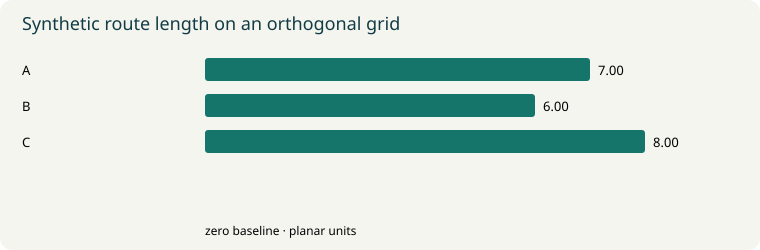

In [2]:
from math import hypot
points = {'A':(3,4),'B':(0,6),'C':(4,4)}
euclidean = {k:hypot(x,y) for k,(x,y) in points.items()}
grid_route = {k:abs(x)+abs(y) for k,(x,y) in points.items()}
print('Straight-line:', euclidean, '\nGrid route:',grid_route)
bars(grid_route, 'Synthetic route length on an orthogonal grid', 'planar units')


## Interpret and extend

A is nearest by straight-line distance; B is nearest by an orthogonal route. Actual travel also depends on roads, crossings, transport, time, cost and exclusion. Change one coordinate and compare both rankings.

Do not label this arbitrary grid as a country or administrative boundary. Spatial uncertainty and aggregation can change a decision. [Explore overlay](../projects/geospatial-analyses-and-maps/index.ipynb) and [metadata discovery](../projects/stac-browser/index.ipynb).

**Source context:** [GISGeography's Periodic Table for Spatial Analysis](https://gisgeography.com/spatial-analysis-periodic-table/) inspires several linked source collections; the diagram and exercise here are original. [STAC specification overview](https://stacspec.org/en/about/stac-spec/).
